# NeuroEdge — SNN  Deteksi Partial Discharge

Notebook ini menjalankan 5 fase persiapan menuju akselerator FPGA (Kria):

| Fase | Isi | Output |
|---|---|---|
| 1 | Eksplorasi data (waveform, spektrum, amplitudo) | grafik + tabel statistik |
| 2 | Split data jujur (block split) + uji leakage | indeks split `.npz` |
| 3 | Normalisasi + level-crossing spike encoding | spike tensor + sparsity |
| 4 | Training SNN + QAT + sweep | model, metrik, kurva |
| 5 | Golden model integer + export | `.mem/.hex/.coe`, test vector |

**Konvensi kelas:** 0 = PD in air, 1 = PD in void, 2 = corona, 3 = no PD (noise).

In [ ]:
from __future__ import annotations

import json
import math
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import snntorch as snn
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------------
# Reproducibility & speed
# ------------------------------------------------------------------
SEED = 42
QUICK = True  

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)  

# ------------------------------------------------------------------
# Paths (cari dataset_1 dari beberapa kemungkinan cwd)
# ------------------------------------------------------------------
candidates = [
    Path.cwd() / "dataset_1",
    Path.cwd() / "source_code" / "dataset_1",
    Path(r"d:\ITS\file\source_code\dataset_1"),
]
DATA_DIR = next((p for p in candidates if p.exists()), None)
assert DATA_DIR is not None, "dataset_1 tidak ditemukan"
ARTIFACT_DIR = DATA_DIR.parent / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = [
    "PD in air (12 kV)",
    "PD in void (25 kV)",
    "Corona (11 kV)",
    "No PD (noise)",
]
FILES = {
    0: "PD_in_Air_12kV.csv",
    1: "PD_in_Void_25kV.csv",
    2: "Corona_11kV.csv",
    3: "Noise_NoPD.csv",
}
FS = 500_000  # sampling rate [Hz]
T = 125       # samples per window (250 us)

# ------------------------------------------------------------------
# Load data (PENTING: separator ';')
# ------------------------------------------------------------------
X_list, y_list = [], []
for label, name in FILES.items():
    df = pd.read_csv(DATA_DIR / name, header=None, sep=";")
    arr = df.to_numpy(dtype=np.float32)
    assert arr.shape == (1000, T), f"{name}: {arr.shape}"
    X_list.append(arr)
    y_list.append(np.full(len(arr), label, dtype=np.int64))

X_raw = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

print(f"X: {X_raw.shape}  y: {y.shape}  per kelas: {np.bincount(y).tolist()}")
print(f"torch {torch.__version__} | snntorch {snn.__version__} | CUDA {torch.cuda.is_available()}")
print(f"data dir: {DATA_DIR}")
print(f"artifacts: {ARTIFACT_DIR}")

X: (4000, 125)  y: (4000,)  per kelas: [1000, 1000, 1000, 1000]
torch 2.14.1+cpu | snntorch 1.0.0 | CUDA False
data dir: d:\ITS\beasiswa\ic icdec\source_code\dataset_1
artifacts: d:\ITS\beasiswa\ic icdec\source_code\artifacts


## Fase 1 — Eksplorasi data

Tujuan fase ini bukan sekadar "lihat data", tetapi menjawab tiga pertanyaan:

1. **Apakah pulsa PD terlihat jelas** dalam window 250 µs, dan posisinya konsisten?
2. **Apakah spektrum tiap kelas berbeda** (mis. corona punya pulsa berulang, noise broadband)?
3. **Apakah amplitudo antar kelas berbeda jauh?** Ini penting: jika kelas bisa dipisahkan hanya dari energi/peak, model bisa belajar karakter sesi rekaman (gain sensor, jarak, tegangan), bukan karakter fisik PD. Perbedaan seperti ini harus dicatat sebagai *limitation* di proposal.

Window hanya 125 sampel pada 500 kS/s, jadi resolusi frekuensi FFT adalah $500\,\text{kHz}/125 = 4\,\text{kHz}$, dan frekuensi maksimum yang bisa diamati adalah 250 kHz (Nyquist).

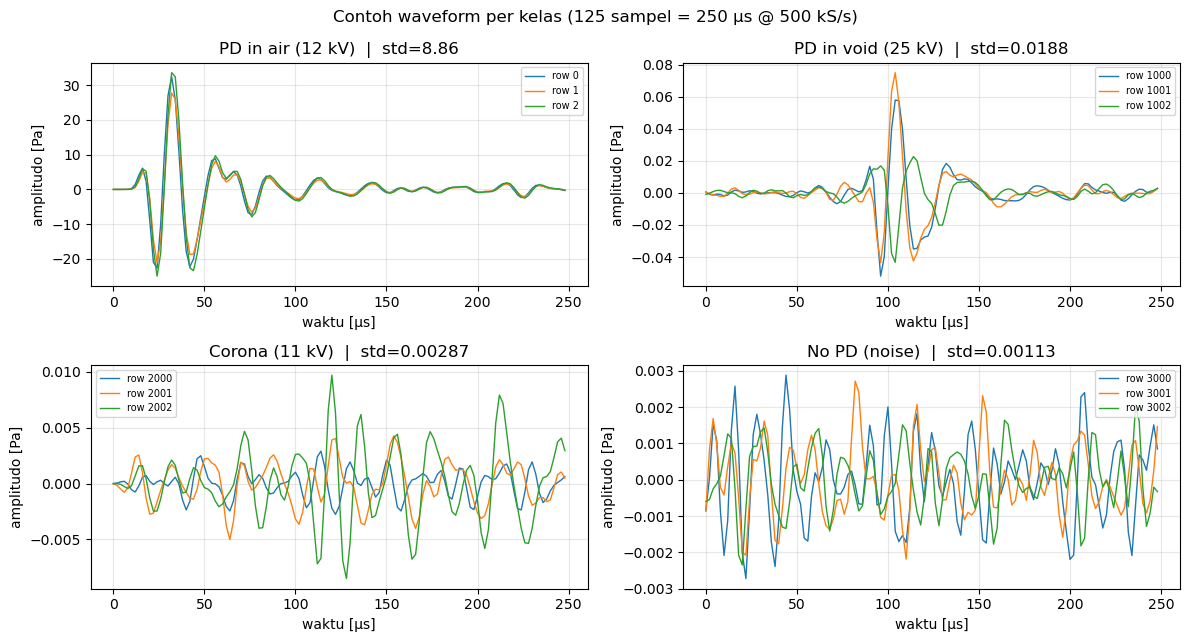

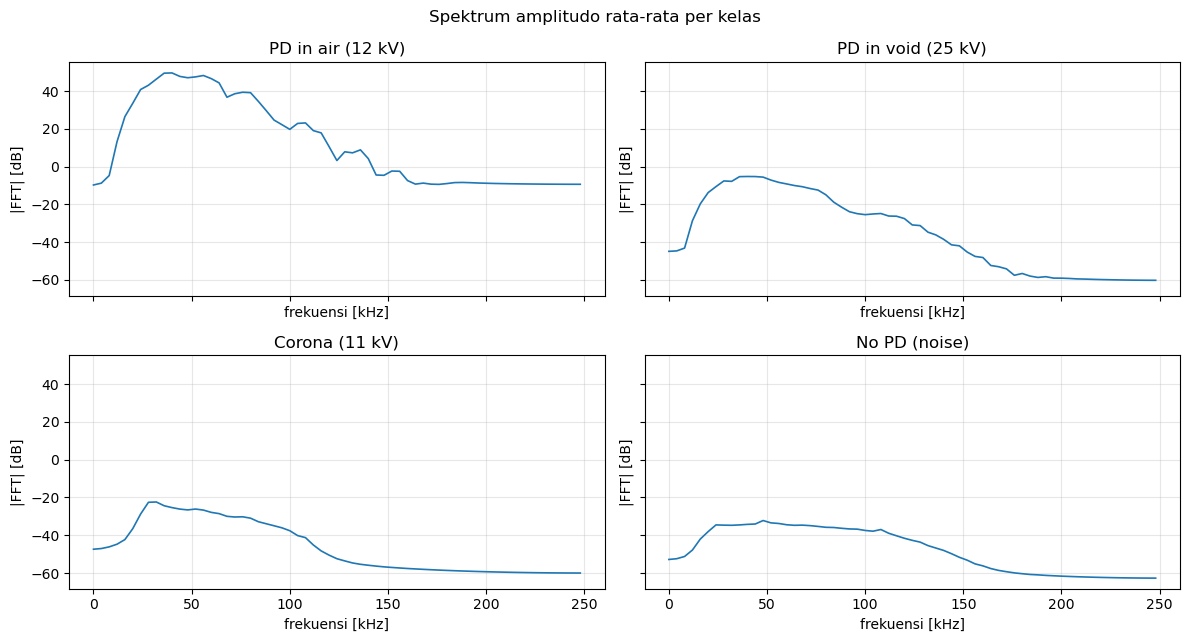

             class  RMS mean   RMS min  RMS max  peak mean  peak min  peak max
 PD in air (12 kV)      8.76     4.132    12.13      40.55     19.27     54.94
PD in void (25 kV)   0.01818  0.001143  0.03823    0.08453  0.002873    0.1821
    Corona (11 kV)  0.002445  0.001083  0.01438   0.007864  0.002239   0.05093
     No PD (noise)  0.001122 0.0007752 0.001685   0.003092  0.001961  0.005115

Rasio peak rata-rata terhadap kelas noise:
             class  peak / noise
 PD in air (12 kV)       13113.9
PD in void (25 kV)          27.3
    Corona (11 kV)           2.5
     No PD (noise)           1.0


In [4]:
t_us = np.arange(T) / FS * 1e6

# ------------------------------------------------------------------
# 1) Waveform domain waktu
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for c, ax in enumerate(axes.ravel()):
    idx = np.where(y == c)[0][:3]
    for i in idx:
        ax.plot(t_us, X_raw[i], lw=1.0, label=f"row {i}")
    ax.set_title(f"{CLASS_NAMES[c]}  |  std={X_raw[y == c].std():.3g}")
    ax.set_xlabel("waktu [µs]")
    ax.set_ylabel("amplitudo [Pa]")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.suptitle("Contoh waveform per kelas (125 sampel = 250 µs @ 500 kS/s)")
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 2) Spektrum amplitudo rata-rata
# ------------------------------------------------------------------
freqs_khz = np.fft.rfftfreq(T, d=1 / FS) / 1e3
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey=True)
for c, ax in enumerate(axes.ravel()):
    mag = np.abs(np.fft.rfft(X_raw[y == c], axis=1)).mean(axis=0)
    ax.plot(freqs_khz, 20 * np.log10(mag + 1e-12), lw=1.2)
    ax.set_title(CLASS_NAMES[c])
    ax.set_xlabel("frekuensi [kHz]")
    ax.set_ylabel("|FFT| [dB]")
    ax.grid(alpha=0.3)
fig.suptitle("Spektrum amplitudo rata-rata per kelas")
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 3) Statistik amplitudo per kelas
# ------------------------------------------------------------------
rows = []
for c in range(4):
    d = X_raw[y == c]
    rms = np.sqrt((d ** 2).mean(axis=1))
    peak = np.abs(d).max(axis=1)
    rows.append({
        "class": CLASS_NAMES[c],
        "RMS mean": rms.mean(),
        "RMS min": rms.min(),
        "RMS max": rms.max(),
        "peak mean": peak.mean(),
        "peak min": peak.min(),
        "peak max": peak.max(),
    })

stats_df = pd.DataFrame(rows)
print(stats_df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

noise_peak = stats_df.loc[3, "peak mean"]
stats_df["peak / noise"] = stats_df["peak mean"] / noise_peak
print("\nRasio peak rata-rata terhadap kelas noise:")
print(stats_df[["class", "peak / noise"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

stats_df.to_csv(ARTIFACT_DIR / "phase1_amplitude_stats.csv", index=False)

# print("\nCatatan penting untuk proposal:")
# print("- Amplitudo antar kelas berbeda beberapa orde besaran (lihat kolom peak/noise).")
# print("- Artinya, model bisa 'curang' dengan hanya memakai energi/amplitudo.")
# print("- Karena itu Fase 3 memakai normalisasi per-window sebagai default, dan hasil")
# print("  normalisasi global dilaporkan sebagai pembanding/limitation.")

## Fase 2 — Split data

Baris-baris dalam satu file kemungkinan berasal dari rekaman kontinu yang dipotong per window. Jika tetangga dekat (baris 500 dan 501) masuk ke train dan test sekaligus, model bisa menghafal waveform yang hampir identik → **leakage** dan akurasi test terlihat tinggi padahal tidak generalisasi.

Karena itu dipakai **block split per kelas**:

- train: baris 0–699
- validasi: baris 700–849
- test: baris 850–999

Dua diagnosis yang dijalankan:

1. **Korelasi baris berdekatan vs berjauhan.** Jika tetangga sangat berkorelasi, block split wajib.
2. **1-NN pada waveform ternormalisasi.** 1-NN sangat sensitif terhadap sampel yang hampir duplikat; selisih akurasi random vs block adalah sinyal leakage yang cukup jelas.

Indeks split disimpan ke `artifacts/phase2_splits.npz` agar bisa dipakai ulang oleh golden model, RTL testbench, dan board.

In [ ]:
N_PER_CLASS = 1000
TRAIN_END, VAL_END = 700, 850


def block_split():
    tr, va, te = [], [], []
    for c in range(4):
        base = c * N_PER_CLASS
        tr += list(range(base, base + TRAIN_END))
        va += list(range(base + TRAIN_END, base + VAL_END))
        te += list(range(base + VAL_END, base + N_PER_CLASS))
    return np.array(tr), np.array(va), np.array(te)


def random_split(seed=SEED):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in range(4):
        idx = np.arange(c * N_PER_CLASS, (c + 1) * N_PER_CLASS)
        perm = rng.permutation(idx)
        tr += list(perm[:700])
        va += list(perm[700:850])
        te += list(perm[850:])
    return np.array(tr), np.array(va), np.array(te)


split_idx = {"block": block_split(), "random": random_split()}

np.savez(
    ARTIFACT_DIR / "phase2_splits.npz",
    **{
        f"{name}_{part}": arr
        for name, parts in split_idx.items()
        for part, arr in zip(("train", "val", "test"), parts)
    },
    seed=np.array(SEED),
)

for name, (tr, va, te) in split_idx.items():
    print(
        f"{name:6s} | train {len(tr)}  val {len(va)}  test {len(te)} | "
        f"kelas train {np.bincount(y[tr]).tolist()}"
    )

# ------------------------------------------------------------------
# Diagnosis 1: korelasi baris berdekatan vs berjauhan
# ------------------------------------------------------------------
def pearson(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


print("\nKorelasi waveform:")
for c in range(4):
    idx = np.arange(c * 1000, (c + 1) * 1000)
    adj = [pearson(X_raw[idx[i]], X_raw[idx[i + 1]]) for i in range(len(idx) - 1)]
    far = [pearson(X_raw[idx[i]], X_raw[idx[(i + 100) % 1000]]) for i in range(0, 1000, 20)]
    print(
        f"  {CLASS_NAMES[c]:20s} adjacent {np.mean(adj):+.3f} | "
        f"jarak-100 {np.mean(far):+.3f}"
    )

# ------------------------------------------------------------------
# Diagnosis 2: 1-NN pada waveform (dinormalisasi per-window)
# ------------------------------------------------------------------
X_norm = X_raw / (np.abs(X_raw).max(axis=1, keepdims=True) + 1e-12)


print("\n1-NN (indikasi leakage):")
knn_scores = {}
for name, (tr, va, te) in split_idx.items():
    knn = KNeighborsClassifier(n_neighbors=1).fit(X_norm[tr], y[tr])
    knn_scores[name] = {
        "val": knn.score(X_norm[va], y[va]),
        "test": knn.score(X_norm[te], y[te]),
    }
    print(f"  {name:6s} | val {knn_scores[name]['val']:.4f} | "
          f"test {knn_scores[name]['test']:.4f}")

gap = knn_scores["random"]["test"] - knn_scores["block"]["test"]
print(f"\nSelisih test 1-NN (random - block): {gap:+.4f}")
# print("Jika selisih besar, ada indikasi leakage; angka block split lebih jujur.")

block  | train 2800  val 600  test 600 | kelas train [700, 700, 700, 700]
random | train 2800  val 600  test 600 | kelas train [700, 700, 700, 700]

Korelasi waveform:
  PD in air (12 kV)    adjacent +0.969 | jarak-100 +0.928
  PD in void (25 kV)   adjacent +0.363 | jarak-100 +0.329
  Corona (11 kV)       adjacent +0.001 | jarak-100 -0.012
  No PD (noise)        adjacent -0.003 | jarak-100 -0.015

1-NN (indikasi leakage):
  block  | val 0.7450 | test 0.7383
  random | val 0.7517 | test 0.7433

Selisih test 1-NN (random - block): +0.0050


## Fase 3 — Normalisasi dan spike encoding

### Normalisasi

Dua opsi diuji:

- **per-window:** bagi setiap window dengan peak absolut window itu. Amplitudo relatif antar window hilang, jadi model dipaksa memakai *bentuk* waveform.
- **global:** bagi semua data dengan peak absolut data train. Amplitudo relatif dipertahankan, tetapi pada dataset ini kelas `air` punya amplitudo ~1000× kelas `noise`, sehingga kelas kecil bisa "tenggelam" saat diskalakan global.

### Level-crossing (delta) encoding

Untuk setiap pasangan sampel berurutan, hitung $\Delta x_t = x_t - x_{t-1}$. Dengan $K=4$ ambang positif $(\theta_1 < \theta_2 < \theta_3 < \theta_4)$:

- channel 0–3 menembak jika $\Delta x_t \ge \theta_k$ (sinyal naik),
- channel 4–7 menembak jika $\Delta x_t \le -\theta_k$ (sinyal turun).

Implementasi di sini **independent comparator**: satu delta besar boleh menembak beberapa channel sekaligus (mis. $\Delta x$ melewati $\theta_1$ dan $\theta_2$). Ini mempertahankan informasi magnitudo delta dan cocok dengan hardware: 8 comparator paralel, tanpa priority encoder.

Hasilnya tensor biner `(N, 125, 8)`. Dua metrik sparsity yang dilaporkan:

- **spike per window** — rata-rata jumlah event; menentukan jumlah MAC event-driven.
- **fraksi timestep aktif** — berapa persen dari 125 timestep yang punya minimal satu spike.

Ambang ditentukan dari **kuantil $|\Delta x|$ data train**, lalu diskalakan pada validasi. Skala ambang yang terlalu kecil → terlalu banyak spike (boros energi); terlalu besar → sinyal hilang.

In [ ]:
K = 4
QUANTILES = (0.50, 0.75, 0.90, 0.97)


def normalize_per_window(X):
    return X / (np.abs(X).max(axis=1, keepdims=True) + 1e-12)


def normalize_global(X, train_idx):
    return X / (np.abs(X[train_idx]).max() + 1e-12)


def threshold_bank(deltas, quantiles=QUANTILES, scale=1.0):
    th = np.quantile(np.abs(deltas), quantiles) * scale
    return np.maximum(th, 1e-9)


def delta_encode(Xn, thresholds):

    d = np.diff(Xn, axis=1, prepend=Xn[:, :1])
    K_ = len(thresholds)
    S = np.zeros((len(Xn), T, 2 * K_), dtype=np.uint8)
    for k, th in enumerate(thresholds):
        S[:, :, k] = (d >= th).astype(np.uint8)
        S[:, :, K_ + k] = (d <= -th).astype(np.uint8)
    return S


def sparsity_report(S, y_true, name):
    per_window = S.sum(axis=(1, 2))
    active_ts = (S.sum(axis=2) > 0).mean()
    density = S.mean()
    print(f"\n[{name}] spike/window: mean {per_window.mean():.1f} | "
          f"min {per_window.min()} | max {per_window.max()}")
    print(f"[{name}] timestep aktif: {active_ts:.1%} | "
          f"density channel-timestep: {density:.2%}")
    for c in range(4):
        m = y_true == c
        print(f"   {CLASS_NAMES[c]:20s} spike/window {per_window[m].mean():7.1f}")
    print(f"[{name}] pemakaian channel (total): {S.sum(axis=(0, 1)).tolist()}")
    return {
        "name": name,
        "spikes_per_window_mean": float(per_window.mean()),
        "active_timestep_fraction": float(active_ts),
        "density": float(density),
        "per_class_spikes": [
            float(per_window[y_true == c].mean()) for c in range(4)
        ],
    }


# ------------------------------------------------------------------
# Encode dengan dua strategi normalisasi
# ------------------------------------------------------------------
tr, va, te = split_idx["block"]

Xn_pw = normalize_per_window(X_raw)
th_pw = threshold_bank(np.diff(Xn_pw[tr], axis=1))
S_pw = delta_encode(Xn_pw, th_pw)

Xn_gl = normalize_global(X_raw, tr)
th_gl = threshold_bank(np.diff(Xn_gl[tr], axis=1))
S_gl = delta_encode(Xn_gl, th_gl)

print("Ambang per-window :", np.round(th_pw, 5).tolist())
print("Ambang global     :", np.round(th_gl, 8).tolist())

sparsity_pw = sparsity_report(S_pw, y, "per_window")
sparsity_gl = sparsity_report(S_gl, y, "global")

# simpan konfigurasi encoding dasar (ambang final ditentukan di Fase 4)
np.savez(
    ARTIFACT_DIR / "phase3_encoding_base.npz",
    K=K,
    quantiles=np.array(QUANTILES),
    thresholds_per_window=th_pw,
    thresholds_global=th_gl,
    normalization_policy=np.array("per-window default; global as comparison"),
)

Ambang per-window : [0.05629, 0.20012, 0.38007, 0.54881]
Ambang global     : [2.283e-05, 0.0006073, 0.02116226, 0.10514786]

[per_window] spike/window: mean 109.2 | min 28 | max 270
[per_window] timestep aktif: 49.7% | density channel-timestep: 10.92%
   PD in air (12 kV)    spike/window    45.2
   PD in void (25 kV)   spike/window    43.1
   Corona (11 kV)       spike/window   145.8
   No PD (noise)        spike/window   202.8
[per_window] pemakaian channel (total): [126400, 60861, 24127, 8316, 122058, 63253, 25296, 6556]

[global] spike/window: mean 109.5 | min 4 | max 329
[global] timestep aktif: 49.6% | density channel-timestep: 10.95%
   PD in air (12 kV)    spike/window   308.6
   PD in void (25 kV)   spike/window    71.8
   Corona (11 kV)       spike/window    36.0
   No PD (noise)        spike/window    21.4
[global] pemakaian channel (total): [124162, 60250, 25490, 7565, 124082, 64085, 24700, 7477]


## Fase 4 — Training SNN dengan surrogate gradient

### Arsitektur

```
8 input (spike) -> Linear 8xH -> LIF(H) -> Linear Hx4 -> LIF(4) -> spike count -> argmax
```

- `H` di-sweep: 16 / 32 / 64 / 128.
- Tanpa bias (biar tidak ada kompensasi DC di hardware; bisa ditambahkan sebagai integer bias nanti).
- `beta = 0.875 = 1 - 2^-3` → implementasi hardware: `mem = mem - (mem >> 3)`.
- `reset_mechanism = "subtract"` → `mem -= threshold` saat spike.
- `gain = 2` → arus dikali 2, implementasi hardware cukup shift kiri 1 bit (gratis).
- Readout: jumlah spike output selama 125 timestep. Di FPGA cukup 4 counter + argmax.

### Surrogate gradient

Spike adalah fungsi step yang turunannya nol di mana-mana. Saat backward, snnTorch mengganti turunan step dengan **fast sigmoid surrogate** (kemiringan 25). Ini membuat gradient bisa mengalir ke bobot walau forward-pass-nya biner.

### Quantization-aware training (QAT)

Bobot di-fake-quantize setiap forward:

$$w_q = \operatorname{round}\!\left(\operatorname{clamp}\!\left(\frac{w}{s}, -q_{max}, q_{max}\right)\right)\cdot s,
\qquad q_{max} = 2^{b-1}-1$$

dengan $s = \max|w| / q_{max}$ per tensor. Saat backward dipakai *straight-through estimator* (STE): gradient dilewatkan seolah quantizer tidak ada. Ini membuat bobot terbiasa dengan grid int8/int6/int4.

### Metrik

- akurasi dan **macro-F1** (4 kelas),
- confusion matrix,
- metrik biner **PD vs noise** (precision, recall, F1),
- akurasi vs jumlah parameter dan vs bit weight.

Dataset seimbang (1000 per kelas), jadi akurasi biasa tetap valid; macro-F1 ditambahkan agar tidak bias ke kelas mayoritas.

In [8]:
# ------------------------------------------------------------------
# Hardware-friendly model
# ------------------------------------------------------------------
def fake_quant(w, bits):
    """Symmetric per-tensor fake quantization with straight-through estimator."""
    qmax = 2 ** (bits - 1) - 1
    scale = w.detach().abs().max().clamp_min(1e-8) / qmax
    wq = torch.clamp(torch.round(w / scale), -qmax, qmax) * scale
    return w + (wq - w).detach()


class SNN4LIF(nn.Module):
    """8 -> H LIF -> 4 LIF. Readout = spike count (argmax)."""

    def __init__(self, n_in=8, hidden=64, n_out=4, num_steps=T,
                 beta=0.875, threshold=0.5, gain=2.0, bits=8):
        super().__init__()
        self.num_steps = num_steps
        self.beta = beta
        self.threshold = threshold
        self.gain = gain
        self.bits = bits
        self.quantize = True

        self.fc1 = nn.Linear(n_in, hidden, bias=False)
        self.lif1 = snn.Leaky(beta=beta, threshold=threshold,
                              reset_mechanism="subtract", init_hidden=True)
        self.fc2 = nn.Linear(hidden, n_out, bias=False)
        self.lif2 = snn.Leaky(beta=beta, threshold=threshold,
                              reset_mechanism="subtract", init_hidden=True)

    def forward(self, x):
        self.lif1.reset_hidden()
        self.lif2.reset_hidden()
        w1 = fake_quant(self.fc1.weight, self.bits) if self.quantize else self.fc1.weight
        w2 = fake_quant(self.fc2.weight, self.bits) if self.quantize else self.fc2.weight

        out = []
        for t in range(self.num_steps):
            spk1 = self.lif1(self.gain * F.linear(x[:, t], w1))
            spk2 = self.lif2(self.gain * F.linear(spk1, w2))
            out.append(spk2)
        return torch.stack(out).sum(0)


class SNNLinearReadout(nn.Module):
    """Alternative: 8 -> H LIF -> H LIF -> linear readout on accumulated spikes.

    Layer terakhir tidak spike; ia menghitung 4 dot-product sekali per window.
    """

    def __init__(self, n_in=8, hidden=64, mid=64, n_out=4, num_steps=T,
                 beta=0.875, threshold=0.5, gain=2.0, bits=8):
        super().__init__()
        self.num_steps = num_steps
        self.gain = gain
        self.bits = bits
        self.quantize = True
        self.fc1 = nn.Linear(n_in, hidden, bias=False)
        self.lif1 = snn.Leaky(beta=beta, threshold=threshold,
                              reset_mechanism="subtract", init_hidden=True)
        self.fc2 = nn.Linear(hidden, mid, bias=False)
        self.lif2 = snn.Leaky(beta=beta, threshold=threshold,
                              reset_mechanism="subtract", init_hidden=True)
        self.fc3 = nn.Linear(mid, n_out, bias=False)

    def forward(self, x):
        self.lif1.reset_hidden()
        self.lif2.reset_hidden()
        w1 = fake_quant(self.fc1.weight, self.bits) if self.quantize else self.fc1.weight
        w2 = fake_quant(self.fc2.weight, self.bits) if self.quantize else self.fc2.weight
        w3 = fake_quant(self.fc3.weight, self.bits) if self.quantize else self.fc3.weight

        counts = torch.zeros(len(x), self.fc3.in_features)
        for t in range(self.num_steps):
            spk1 = self.lif1(self.gain * F.linear(x[:, t], w1))
            spk2 = self.lif2(self.gain * F.linear(spk1, w2))
            counts = counts + spk2
        return F.linear(counts, w3)


# ------------------------------------------------------------------
# Training / evaluation helpers
# ------------------------------------------------------------------
@torch.no_grad()
def evaluate_loss_acc(model, X, y_, batch_size=512):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y_[i:i + batch_size]
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(xb)
    return total_loss / total, correct / total


@torch.no_grad()
def predict(model, X, batch_size=512):
    model.eval()
    preds = []
    for i in range(0, len(X), batch_size):
        preds.append(model(X[i:i + batch_size]).argmax(1))
    return torch.cat(preds).numpy()


def train_snn(model, Xtr, ytr, Xva, yva, epochs, lr=1e-3,
              batch_size=256, patience=10, verbose=True):
    """Train with a CONSTANT learning rate.

    Catatan: cosine decay pada eksperimen ini membuat val accuracy berhenti
    di ~85%; dengan LR konstan model mencapai ~90-92%. Untuk model kecil
    dengan surrogate gradient, LR konstan lebih stabil.
    """
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_epoch, best_state = -1.0, -1, None

    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr))
        tr_loss, tr_correct = 0.0, 0
        for i in range(0, len(Xtr), batch_size):
            b = perm[i:i + batch_size]
            xb, yb = Xtr[b], ytr[b]
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            tr_loss += loss.item() * len(b)
            tr_correct += (logits.argmax(1) == yb).sum().item()

        va_loss, va_acc = evaluate_loss_acc(model, Xva, yva)
        hist["train_loss"].append(tr_loss / len(Xtr))
        hist["train_acc"].append(tr_correct / len(Xtr))
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)

        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  epoch {ep:3d}/{epochs} | train {hist['train_acc'][-1]:.4f} | "
                  f"val {va_acc:.4f} | lr {lr:.2e}")

        if ep - best_epoch >= patience:
            if verbose:
                print(f"  early stop (best epoch {best_epoch})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, {"val_acc": best_acc, "epoch": best_epoch}


def metrics_report(y_true, y_pred, name="", show=True):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    acc = accuracy_score(y_true, y_pred)
    macro = f1_score(y_true, y_pred, average="macro")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(4))
    bin_true = (y_true != 3).astype(int)
    bin_pred = (y_pred != 3).astype(int)
    p, r, f, _ = precision_recall_fscore_support(
        bin_true, bin_pred, average="binary", pos_label=1, zero_division=0
    )
    if show:
        print(f"\n=== {name} ===")
        print(f"accuracy {acc:.4f} | macro-F1 {macro:.4f}")
        print(f"PD vs noise: precision {p:.4f} | recall {r:.4f} | F1 {f:.4f}")
        print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    return {
        "name": name,
        "accuracy": float(acc),
        "macro_f1": float(macro),
        "pd_vs_noise": {"precision": float(p), "recall": float(r), "f1": float(f)},
        "confusion_matrix": cm.tolist(),
    }


def plot_history(hist, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(hist["train_loss"], label="train")
    axes[0].plot(hist["val_loss"], label="val")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
    axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(hist["train_acc"], label="train")
    axes[1].plot(hist["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout(); plt.show()


def plot_confusion(cm, title=""):
    cm = np.asarray(cm)
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8)
    ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout(); plt.show()

Normalisasi utama: per_window (menghindari amplitude shortcut)
Ambang dasar: [0.05629, 0.20012, 0.38007, 0.54881]
scale 0.50 | val 0.8517 | test 0.8550 | spike/window 183.1
scale 1.00 | val 0.8050 | test 0.8083 | spike/window 109.2

 scale  val_acc  test_acc  spikes_per_window  active_timestep_frac
0.5000   0.8517    0.8550           183.1002                0.6293
1.0000   0.8050    0.8083           109.2168                0.4969

Skala ambang terpilih: 0.5
Ambang final: [0.02814, 0.10006, 0.19004, 0.27441]
Spike/window final: 183.1

=== Training model final 8-128-4 (per-window) ===
  epoch   1/100 | train 0.2861 | val 0.4533 | lr 1.00e-03
  epoch   2/100 | train 0.4371 | val 0.3617 | lr 1.00e-03
  epoch   3/100 | train 0.4904 | val 0.5483 | lr 1.00e-03
  epoch   4/100 | train 0.5961 | val 0.6433 | lr 1.00e-03
  epoch   5/100 | train 0.6454 | val 0.6183 | lr 1.00e-03
  epoch   6/100 | train 0.7061 | val 0.7000 | lr 1.00e-03
  epoch   7/100 | train 0.7457 | val 0.7900 | lr 1.00e-03
  ep

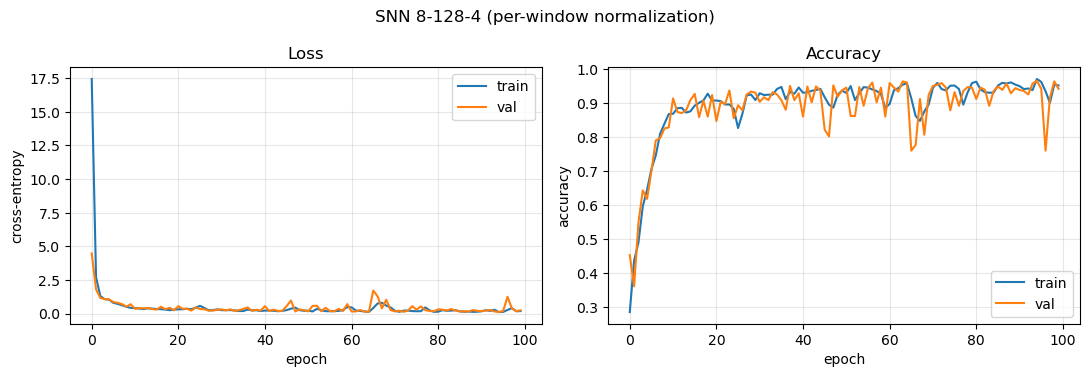

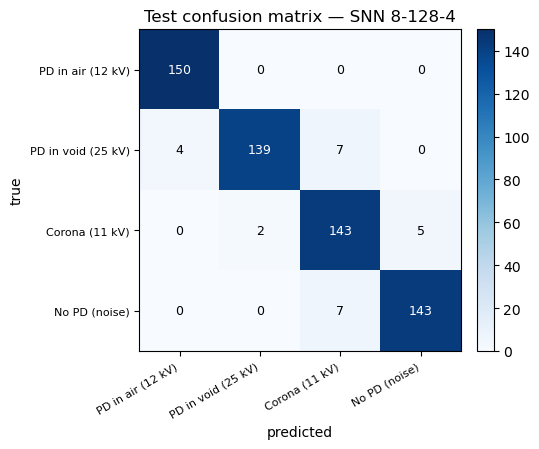


=== Pembanding: normalisasi global ===

=== Global normalization (comparison) ===
accuracy 0.9317 | macro-F1 0.9320
PD vs noise: precision 0.9600 | recall 0.9600 | F1 0.9600
                    precision    recall  f1-score   support

 PD in air (12 kV)     1.0000    1.0000    1.0000       150
PD in void (25 kV)     0.9932    0.9733    0.9832       150
    Corona (11 kV)     0.8562    0.8733    0.8647       150
     No PD (noise)     0.8800    0.8800    0.8800       150

          accuracy                         0.9317       600
         macro avg     0.9324    0.9317    0.9320       600
      weighted avg     0.9324    0.9317    0.9320       600


Catatan: akurasi global bisa lebih tinggi karena amplitudo dipertahankan.
Dataset ini punya peak/noise > 10.000x, jadi angka global adalah batas atas
yang mencampur karakter PD dengan gain/sesi rekaman. Untuk klaim generalisasi,
gunakan angka per-window.

Tersimpan: d:\ITS\beasiswa\ic icdec\source_code\artifacts\phase6_model.pt
Tersimpan: 

In [17]:
y_t = torch.from_numpy(y)
tr, va, te = split_idx["block"]

EPOCHS_FINAL = 100
EPOCHS_SWEEP = 15 if QUICK else 20
EPOCHS_COMPARE = 20 if QUICK else 30

S_map = {
    "per_window": torch.from_numpy(S_pw).float(),
    "global": torch.from_numpy(S_gl).float(),
}
Xn_map = {"per_window": Xn_pw, "global": Xn_gl}
th_map = {"per_window": th_pw, "global": th_gl}

# ------------------------------------------------------------------
# 1) Pilihan normalisasi utama: per-window
# ------------------------------------------------------------------
# Global normalization TIDAK dipilih sebagai model utama, walaupun bisa
# memberi akurasi lebih tinggi, karena amplitudo antar kelas berbeda
# ~4 orde besaran (peak/noise > 10.000x). Model global bisa belajar
# "sidik jari" gain/sesi rekaman, bukan karakter fisik PD.
best_norm = "per_window"
base_th = th_map[best_norm]
Xn_best = Xn_map[best_norm]
print(f"Normalisasi utama: {best_norm} (menghindari amplitude shortcut)")
print(f"Ambang dasar: {np.round(base_th, 5).tolist()}")

# ------------------------------------------------------------------
# 2) Tuning skala ambang pada validasi
# ------------------------------------------------------------------
scales = [0.5, 1.0] if QUICK else [0.5, 0.75, 1.0, 1.5]
thr_rows = []

for scale in scales:
    th = base_th * scale
    S = delta_encode(Xn_best, th)
    St = torch.from_numpy(S).float()
    model = SNN4LIF(hidden=32, bits=8)
    model, hist, best = train_snn(
        model, St[tr], y_t[tr], St[va], y_t[va],
        epochs=EPOCHS_SWEEP, patience=EPOCHS_SWEEP, verbose=False,
    )
    pred = predict(model, St[te])
    acc = accuracy_score(y[te], pred)
    thr_rows.append({
        "scale": scale,
        "val_acc": float(best["val_acc"]),
        "test_acc": float(acc),
        "spikes_per_window": float(S.sum(axis=(1, 2)).mean()),
        "active_timestep_frac": float((S.sum(axis=2) > 0).mean()),
    })
    print(f"scale {scale:.2f} | val {best['val_acc']:.4f} | test {acc:.4f} "
          f"| spike/window {S.sum(axis=(1, 2)).mean():.1f}")

thr_df = pd.DataFrame(thr_rows)
print("\n" + thr_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

best_scale = float(thr_df.loc[thr_df["val_acc"].idxmax(), "scale"])
th_final = base_th * best_scale
S_final = delta_encode(Xn_best, th_final)
S_final_t = torch.from_numpy(S_final).float()

print(f"\nSkala ambang terpilih: {best_scale}")
print(f"Ambang final: {np.round(th_final, 5).tolist()}")
print(f"Spike/window final: {S_final.sum(axis=(1, 2)).mean():.1f}")

# ------------------------------------------------------------------
# 3) Model final 8 -> 128 LIF -> 4 LIF (per-window)
# ------------------------------------------------------------------
print("\n=== Training model final 8-128-4 (per-window) ===")
model_final = SNN4LIF(hidden=128, bits=8)
t0 = time.time()
model_final, hist_final, best_final = train_snn(
    model_final, S_final_t[tr], y_t[tr], S_final_t[va], y_t[va],
    epochs=EPOCHS_FINAL, patience=EPOCHS_FINAL, verbose=True,
)
print(f"training time: {time.time() - t0:.0f}s | best epoch {best_final['epoch']} "
      f"| best val {best_final['val_acc']:.4f}")

y_pred_final = predict(model_final, S_final_t[te])
final_metrics = metrics_report(y[te], y_pred_final, "SNN 8-128-4, per-window")

plot_history(hist_final, "SNN 8-128-4 (per-window normalization)")
plot_confusion(final_metrics["confusion_matrix"], "Test confusion matrix — SNN 8-128-4")

# ------------------------------------------------------------------
# 4) Pembanding: normalisasi global (batas atas / amplitude shortcut)
# ------------------------------------------------------------------
print("\n=== Pembanding: normalisasi global ===")
th_gl_final = th_gl * best_scale
S_gl_final = delta_encode(Xn_gl, th_gl_final)
S_gl_final_t = torch.from_numpy(S_gl_final).float()

model_gl = SNN4LIF(hidden=128, bits=8)
model_gl, hist_gl, best_gl = train_snn(
    model_gl, S_gl_final_t[tr], y_t[tr], S_gl_final_t[va], y_t[va],
    epochs=EPOCHS_COMPARE, patience=10, verbose=False,
)
pred_gl = predict(model_gl, S_gl_final_t[te])
global_metrics = metrics_report(y[te], pred_gl, "Global normalization (comparison)")
print("\nCatatan: akurasi global bisa lebih tinggi karena amplitudo dipertahankan.")
print("Dataset ini punya peak/noise > 10.000x, jadi angka global adalah batas atas")
print("yang mencampur karakter PD dengan gain/sesi rekaman. Untuk klaim generalisasi,")
print("gunakan angka per-window.")

norm_results = {
    "per_window_main": final_metrics,
    "global_comparison": global_metrics,
}

# ------------------------------------------------------------------
# 5) Simpan model + encoding + metrik
# ------------------------------------------------------------------
torch.save(
    {
        "state_dict": model_final.state_dict(),
        "config": {
            "model": "SNN4LIF",
            "n_in": 8,
            "hidden": 128,
            "n_out": 4,
            "num_steps": T,
            "beta": 0.875,
            "threshold": 0.5,
            "gain": 2.0,
            "bits": 8,
            "class_names": CLASS_NAMES,
        },
        "encoding": {
            "normalization": best_norm,
            "K": K,
            "quantiles": list(QUANTILES),
            "thresholds": th_final.tolist(),
            "scale": best_scale,
        },
        "split": "block: train 0-699, val 700-849, test 850-999 per class",
    },
    ARTIFACT_DIR / "phase6_model.pt",
)

np.savez(
    ARTIFACT_DIR / "phase3_encoding_final.npz",
    thresholds=th_final,
    normalization=np.array(best_norm),
    scale=np.array(best_scale),
    spikes_per_window=S_final.sum(axis=(1, 2)),
)

with open(ARTIFACT_DIR / "phase6_metrics.json", "w", encoding="utf-8") as f:
    json.dump(
        {"threshold_sweep": thr_rows, "normalization": norm_results},
        f, indent=2,
    )

print(f"\nTersimpan: {ARTIFACT_DIR / 'phase6_model.pt'}")
print(f"Tersimpan: {ARTIFACT_DIR / 'phase6_metrics.json'}")

 split  val_acc  test_acc  macro_f1
 block   0.8783    0.8700    0.8712
random   0.8683    0.8833    0.8818

Selisih test (random - block): +0.0133
Selisih besar (> beberapa persen) = indikasi leakage pada random split.
hidden  16 | val 0.4300 | test 0.3917
hidden  32 | val 0.6217 | test 0.6117
hidden  64 | val 0.6367 | test 0.6583
hidden 128 | val 0.8283 | test 0.8183

 hidden  params  val_acc  test_acc  macro_f1
     16     192   0.4300    0.3917    0.3710
     32     384   0.6217    0.6117    0.6085
     64     768   0.6367    0.6583    0.6129
    128    1536   0.8283    0.8183    0.8148
bits 8 | val 0.8500 | test 0.8500
bits 6 | val 0.7783 | test 0.7700
bits 4 | val 0.5617 | test 0.5183

 bits  val_acc  test_acc  macro_f1
    4   0.5617    0.5183    0.4829
    6   0.7783    0.7700    0.7657
    8   0.8500    0.8500    0.8489


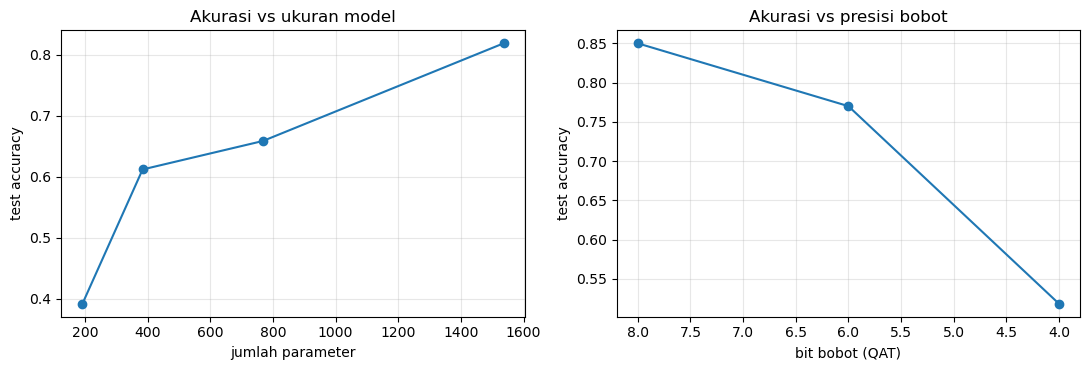


=== Linear readout (8-128-128-linear) ===
accuracy 0.9383 | macro-F1 0.9383
PD vs noise: precision 0.9954 | recall 0.9689 | F1 0.9820
                    precision    recall  f1-score   support

 PD in air (12 kV)     0.9933    0.9867    0.9900       150
PD in void (25 kV)     0.9850    0.8733    0.9258       150
    Corona (11 kV)     0.8718    0.9067    0.8889       150
     No PD (noise)     0.9136    0.9867    0.9487       150

          accuracy                         0.9383       600
         macro avg     0.9409    0.9383    0.9383       600
      weighted avg     0.9409    0.9383    0.9383       600

waktu: 36s
Catatan: readout linear butuh 128 akumulator + 128x4 MAC sekali per window;
output LIF butuh update 4 neuron setiap timestep. Bandingkan akurasi vs biaya.

Tersimpan: d:\ITS\beasiswa\ic icdec\source_code\artifacts\phase6_sweeps.json


In [19]:
# ------------------------------------------------------------------
# 5) Block split vs random split (uji leakage)
# ------------------------------------------------------------------
EPOCHS_LEAK = 12 if QUICK else 20
EPOCHS_MODEL_SWEEP = 10 if QUICK else 16


def run_split(split_name, epochs):
    tr2, va2, te2 = split_idx[split_name]
    th2 = threshold_bank(np.diff(Xn_best[tr2], axis=1), scale=best_scale)
    S2 = delta_encode(Xn_best, th2)
    S2_t = torch.from_numpy(S2).float()
    model = SNN4LIF(hidden=128, bits=8)
    model, hist, best = train_snn(
        model, S2_t[tr2], y_t[tr2], S2_t[va2], y_t[va2],
        epochs=epochs, patience=epochs, verbose=False,
    )
    pred = predict(model, S2_t[te2])
    return {
        "split": split_name,
        "val_acc": float(best["val_acc"]),
        "test_acc": float(accuracy_score(y[te2], pred)),
        "macro_f1": float(f1_score(y[te2], pred, average="macro")),
    }


leak_rows = [run_split("block", EPOCHS_LEAK), run_split("random", EPOCHS_LEAK)]
leak_df = pd.DataFrame(leak_rows)
print(leak_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nSelisih test (random - block): "
      f"{leak_df.loc[1, 'test_acc'] - leak_df.loc[0, 'test_acc']:+.4f}")
print("Selisih besar (> beberapa persen) = indikasi leakage pada random split.")

# ------------------------------------------------------------------
# 6) Sweep ukuran hidden (parameter vs akurasi)
# ------------------------------------------------------------------
hidden_list = [16, 32, 64, 128]
hidden_rows = []

for h in hidden_list:
    model = SNN4LIF(hidden=h, bits=8)
    model, hist, best = train_snn(
        model, S_final_t[tr], y_t[tr], S_final_t[va], y_t[va],
        epochs=EPOCHS_MODEL_SWEEP, patience=EPOCHS_MODEL_SWEEP, verbose=False,
    )
    pred = predict(model, S_final_t[te])
    hidden_rows.append({
        "hidden": h,
        "params": 8 * h + 4 * h,  # fc1 + fc2, tanpa bias
        "val_acc": float(best["val_acc"]),
        "test_acc": float(accuracy_score(y[te], pred)),
        "macro_f1": float(f1_score(y[te], pred, average="macro")),
    })
    print(f"hidden {h:3d} | val {hidden_rows[-1]['val_acc']:.4f} "
          f"| test {hidden_rows[-1]['test_acc']:.4f}")

hidden_df = pd.DataFrame(hidden_rows).sort_values("hidden").reset_index(drop=True)
print("\n" + hidden_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ------------------------------------------------------------------
# 7) Sweep presisi bobot (QAT)
# ------------------------------------------------------------------
bit_list = [8, 6, 4]
bit_rows = []

for b in bit_list:
    model = SNN4LIF(hidden=128, bits=b)
    model, hist, best = train_snn(
        model, S_final_t[tr], y_t[tr], S_final_t[va], y_t[va],
        epochs=EPOCHS_MODEL_SWEEP, patience=EPOCHS_MODEL_SWEEP, verbose=False,
    )
    pred = predict(model, S_final_t[te])
    bit_rows.append({
        "bits": b,
        "val_acc": float(best["val_acc"]),
        "test_acc": float(accuracy_score(y[te], pred)),
        "macro_f1": float(f1_score(y[te], pred, average="macro")),
    })
    print(f"bits {b} | val {bit_rows[-1]['val_acc']:.4f} | test {bit_rows[-1]['test_acc']:.4f}")

bits_df = pd.DataFrame(bit_rows).sort_values("bits").reset_index(drop=True)
print("\n" + bits_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hidden_df["params"], hidden_df["test_acc"], "o-")
axes[0].set_xlabel("jumlah parameter")
axes[0].set_ylabel("test accuracy")
axes[0].set_title("Akurasi vs ukuran model")
axes[0].grid(alpha=0.3)
axes[1].plot(bits_df["bits"], bits_df["test_acc"], "o-")
axes[1].set_xlabel("bit bobot (QAT)")
axes[1].set_ylabel("test accuracy")
axes[1].set_title("Akurasi vs presisi bobot")
axes[1].invert_xaxis()
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 8) Pembanding: linear readout pada akumulasi spike hidden
# ------------------------------------------------------------------
EPOCHS_ALT = 12 if QUICK else 20
model_alt = SNNLinearReadout(hidden=128, mid=128, bits=8)
t0 = time.time()
model_alt, hist_alt, best_alt = train_snn(
    model_alt, S_final_t[tr], y_t[tr], S_final_t[va], y_t[va],
    epochs=EPOCHS_ALT, patience=10, verbose=False,
)
pred_alt = predict(model_alt, S_final_t[te])
alt_metrics = metrics_report(y[te], pred_alt, "Linear readout (8-128-128-linear)")
print(f"waktu: {time.time() - t0:.0f}s")
print("Catatan: readout linear butuh 128 akumulator + 128x4 MAC sekali per window;")
print("output LIF butuh update 4 neuron setiap timestep. Bandingkan akurasi vs biaya.")

with open(ARTIFACT_DIR / "phase6_sweeps.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "leakage": leak_rows,
            "hidden_sweep": hidden_rows,
            "bit_sweep": bit_rows,
            "linear_readout": alt_metrics,
        },
        f, indent=2,
    )

print(f"\nTersimpan: {ARTIFACT_DIR / 'phase6_sweeps.json'}")

In [ ]:
# ------------------------------------------------------------------
# Visualisasi delta spike encoding per kelas (ambang final th_final)
# ------------------------------------------------------------------
CH_LABELS = [f"+θ{k + 1}" for k in range(K)] + [f"-θ{k + 1}" for k in range(K)]
print(f"Normalisasi: {best_norm} | skala ambang: {best_scale}")
print(f"Ambang final (θ1..θ{K}): {np.round(th_final, 5).tolist()}")

fig, axes = plt.subplots(4, 4, figsize=(20, 11), sharex=True)
for c in range(4):
    i = te[y[te] == c][0]  # sampel test pertama dari kelas c
    xn = Xn_best[i]
    d = np.diff(xn, prepend=xn[:1])  # sama dengan delta_encode
    s = S_final[i]
    n_up = s[:, :K].sum(axis=1).astype(int)    # jumlah ambang naik yang terlewati per timestep
    n_down = s[:, K:].sum(axis=1).astype(int)  # jumlah ambang turun yang terlewati per timestep
    up_t, down_t = n_up > 0, n_down > 0

    # 1) waveform + penanda spike naik/turun
    ax = axes[c, 0]
    ax.plot(t_us, xn, lw=1.0, color="0.4")
    ax.scatter(t_us[up_t], xn[up_t], marker="^", s=14 + 6 * n_up[up_t],
               color="tab:green", label="spike naik", zorder=3)
    ax.scatter(t_us[down_t], xn[down_t], marker="v", s=14 + 6 * n_down[down_t],
               color="tab:red", label="spike turun", zorder=3)
    ax.set_title(f"{CLASS_NAMES[c]} | row {i}")
    ax.set_ylabel("x (ternormalisasi)")
    ax.grid(alpha=0.3)
    if c == 0:
        ax.legend(fontsize=7, loc="upper right")

    # 2) delta + ambang
    ax = axes[c, 1]
    ax.plot(t_us, d, lw=1.0, color="k")
    for k, th in enumerate(th_final):
        col = plt.cm.viridis(k / max(K - 1, 1))
        ax.axhline(th, color=col, ls="--", lw=0.8, label=f"±θ{k + 1}={th:.3g}")
        ax.axhline(-th, color=col, ls="--", lw=0.8)
    ax.set_title("Δx dan ambang ±θk")
    ax.set_ylabel("Δx")
    ax.grid(alpha=0.3)
    if c == 0:
        ax.legend(fontsize=7, loc="upper right")

    # 3) plot spike naik (+) / turun (-): tinggi = jumlah ambang terlewati
    ax = axes[c, 2]
    ax.vlines(t_us[up_t], 0, n_up[up_t], color="tab:green", lw=1.5)
    ax.plot(t_us[up_t], n_up[up_t], "^", color="tab:green", ms=4,
            label=f"naik ({int(s[:, :K].sum())})")
    ax.vlines(t_us[down_t], 0, -n_down[down_t], color="tab:red", lw=1.5)
    ax.plot(t_us[down_t], -n_down[down_t], "v", color="tab:red", ms=4,
            label=f"turun ({int(s[:, K:].sum())})")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylim(-K - 0.5, K + 0.5)
    ax.set_yticks(range(-K, K + 1))
    ax.set_title("Spike naik (+) / turun (−)")
    ax.set_ylabel("level ambang")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")

    # 4) raster 8 channel
    ax = axes[c, 3]
    ax.imshow(s.T, aspect="auto", cmap="Greys", interpolation="nearest",
              extent=[t_us[0], t_us[-1], 2 * K - 0.5, -0.5])
    ax.axhline(K - 0.5, color="tab:blue", lw=0.8)
    ax.set_yticks(range(2 * K))
    ax.set_yticklabels(CH_LABELS, fontsize=8)
    ax.set_title(f"Spike raster | total {int(s.sum())} spike")

for ax in axes[-1]:
    ax.set_xlabel("waktu [µs]")
fig.suptitle("Delta (level-crossing) spike encoding per kelas — ambang final")
fig.tight_layout()
plt.show()

enc_rows = []
for c in range(4):
    Sc = S_final[te][y[te] == c]
    row = {"class": CLASS_NAMES[c]}
    row.update({lbl: v for lbl, v in zip(CH_LABELS, Sc.sum(axis=1).mean(axis=0))})
    row["total"] = Sc.sum(axis=(1, 2)).mean()
    row["timestep aktif"] = (Sc.sum(axis=2) > 0).mean()
    enc_rows.append(row)
enc_df = pd.DataFrame(enc_rows)
print("\nRata-rata spike per window per channel (test set):")
print(enc_df.to_string(index=False, float_format=lambda v: f"{v:.2f}"))


### Plot per channel ("sensor") encoding

Sel berikut menampilkan aktivitas **tiap channel encoding** (4 ambang naik + 4 ambang turun) di seluruh test set:

- **PSTH** (peri-stimulus time histogram): rata-rata spike per timestep untuk setiap kelas. Ini menunjukkan *kapan* tiap channel aktif.
- **Heatmap**: rata-rata jumlah spike per window untuk setiap channel dan kelas. Ini menunjukkan *channel mana* yang dominan untuk tiap kelas.
- **Boxplot**: distribusi total spike per window, untuk melihat sparsity tiap kelas.

## Fase 5 — Golden model bit-accurate (integer murni)

Golden model adalah **satu-satunya referensi kebenaran** untuk RTL dan board. Ia tidak memakai float dan tidak memakai PyTorch. Semantik per layer:

```
cur    = ((W_int @ spike_in) << gain_shift) << frac_bits
mem    = mem - (mem >> decay_shift) + cur
mem    = clamp(mem, -32768, 32767)        # membrane int16
spike  = (mem >= threshold_int)
mem    = mem - spike * threshold_int      # reset by subtraction
```

Detail penting:

- **`decay_shift = -log2(1 - beta)`**. Untuk `beta = 0.875`, shift = 3; untuk `0.9375`, shift = 4. `mem - (mem >> 3)` identik dengan `0.875 * mem` untuk nilai negatif sekalipun (arithmetic shift = floor, sama dengan two's complement di hardware).
- **Bobot int8** disimpan dengan satu `scale` per tensor. `threshold_int = round(threshold / scale * 2^frac_bits)`.
- **`frac_bits = 3`** adalah presisi membran tambahan. Shift decay membuang fraksi tiap langkah; tanpa bit tambahan, error menumpuk dan prediksi bergeser. Dengan `frac_bits=3`, membran masih aman di int16 (0 saturasi pada test set). `frac_bits=6` menyebabkan >278 ribu saturasi dan akurasi jatuh ke ~54%, jadi tidak dipakai.
- Karena input spike hanya 0/1, tiap layer bisa disimulasikan dalam satuan integernya sendiri — **tidak perlu rescaling antar layer**.
- **Saturasi int16** dihitung dan dilaporkan. Kalau saturasi sering terjadi, kurangi `frac_bits`/gain atau perbesar skala.
- `counts` = jumlah spike output selama 125 timestep; prediksi = `argmax(counts)`.

**Kenapa akurasi golden bisa sedikit berbeda dari torch QAT?** Model torch memakai `beta * mem` (float), sedangkan hardware memakai shift yang memotong fraksi. Selisih tipikal ~1–3 poin akurasi dan bukan bug. Golden model tetap referensi untuk RTL. Jika ingin menutup selisih ini sepenuhnya, latih ulang model dengan dinamika shift yang sama (*hardware-aware training*) atau ganti decay menjadi multiplier fixed-point (`mem * beta_q >> 15`).

File `golden_model.py` di folder yang sama berisi implementasi ini dan helper export. Vektor uji (input spike + output yang diharapkan + trace tiap layer) disimpan untuk testbench RTL.

In [ ]:
sys.path.insert(0, str(DATA_DIR.parent))
import importlib
import golden_model as gm
importlib.reload(gm)

# ------------------------------------------------------------------
# 1) Ekstrak parameter integer dari model final
# ------------------------------------------------------------------
def extract_layers(model):
    layers = []
    for fc, lif in ((model.fc1, model.lif1), (model.fc2, model.lif2)):
        layers.append(
            gm.make_layer(
                fc.weight.detach().cpu().numpy(),
                threshold=float(lif.threshold),
                beta=float(lif.beta),
                bits=model.bits,
                gain=model.gain,
            )
        )
    return layers


layers = extract_layers(model_final)
for i, layer in enumerate(layers, 1):
    print(
        f"layer {i}: shape {layer['shape']} | scale {layer['scale']:.6g} | "
        f"threshold_int {layer['threshold_int']} | decay_shift {layer['decay_shift']} | "
        f"gain_shift {layer['gain_shift']} | frac_bits {layer['frac_bits']}"
    )

# ------------------------------------------------------------------
# 2) Jalankan golden model pada test set
# ------------------------------------------------------------------
X_test_spikes = S_final[te].astype(np.uint8)
counts_g, pred_g, sat_events, traces = gm.golden_infer(
    X_test_spikes, layers, return_traces=True
)

pred_t = predict(model_final, S_final_t[te])
agreement = float((pred_g == pred_t).mean())

gold_metrics = metrics_report(y[te], pred_g, "Golden model integer (test)")
print(f"\nTorch (QAT) test accuracy : {final_metrics['accuracy']:.4f}")
print(f"Golden integer test acc  : {gold_metrics['accuracy']:.4f}")
print(f"Prediction agreement      : {agreement:.4%}")
print(f"Saturasi int16            : {sat_events} event")

# ------------------------------------------------------------------
# 3) Hitung biaya event-driven dengan benar
# ------------------------------------------------------------------
# layer-1 MAC = jumlah spike INPUT x jumlah hidden unit
# layer-2 MAC = jumlah spike HIDDEN x jumlah output unit
input_spk_pw = float(np.mean(X_test_spikes.sum(axis=(1, 2))))
hidden_spk_pw = float(np.mean([tr[0].sum() for tr in traces]))
out_spk_pw = float(np.mean([tr[1].sum() for tr in traces]))

mac_layer1 = input_spk_pw * 128
mac_layer2 = hidden_spk_pw * 4
membrane_updates = (128 + 4) * T

print(f"\nSpike rata-rata per window:")
print(f"  input  (8 ch)        : {input_spk_pw:.1f}")
print(f"  hidden (128 neuron)  : {hidden_spk_pw:.1f}")
print(f"  output (4 neuron)    : {out_spk_pw:.1f}")
print(f"Estimasi biaya per window:")
print(f"  layer-1 MAC          : {mac_layer1:.0f}")
print(f"  layer-2 MAC          : {mac_layer2:.0f}")
print(f"  membrane updates     : {membrane_updates}")
print(f"  total MAC (event)    : {mac_layer1 + mac_layer2:.0f}")
print("Bandingkan dengan dense 125 x (8x128 + 128x4) = 192.000 MAC per window.")

# ------------------------------------------------------------------
# 4) Export bobot + parameter + vektor uji
# ------------------------------------------------------------------
out_dir = ARTIFACT_DIR / "phase6_export"
out_dir.mkdir(exist_ok=True)

bits = model_final.bits
for i, layer in enumerate(layers, 1):
    gm.write_mem(out_dir / f"w{i}_int{bits}.mem", layer["w"])
    gm.write_hex(out_dir / f"w{i}_int{bits}.hex", layer["w"])
    gm.write_coe(out_dir / f"w{i}_int{bits}.coe", layer["w"])

gm.save_layers_json(
    out_dir / "params.json",
    layers,
    extra={
        "model": "SNN4LIF",
        "T": T,
        "n_in": 8,
        "hidden": int(model_final.fc1.out_features),
        "n_out": 4,
        "beta": float(model_final.beta),
        "gain": float(model_final.gain),
        "bits": int(model_final.bits),
        "class_names": CLASS_NAMES,
        "normalization": best_norm,
        "thresholds_float": th_final.tolist(),
        "encoding": {"K": K, "quantiles": list(QUANTILES), "scale": best_scale},
        "weight_layout": "row-major (out_units, in_units)",
        "notes": "input spike 0/1, int16 membrane, saturation to [-32768, 32767], reset by subtraction",
    },
)

N_TRACE = min(32, len(te))
np.savez(
    out_dir / "test_vectors.npz",
    X_test=X_test_spikes,
    y_test=y[te].astype(np.int64),
    pred_golden=pred_g,
    counts_golden=counts_g,
    spk_layer1=np.stack([traces[i][0] for i in range(N_TRACE)]),
    spk_layer2=np.stack([traces[i][1] for i in range(N_TRACE)]),
    w1=layers[0]["w"],
    w2=layers[1]["w"],
    threshold_int=np.array([layers[0]["threshold_int"], layers[1]["threshold_int"]]),
    decay_shift=np.array([layers[0]["decay_shift"], layers[1]["decay_shift"]]),
    gain_shift=np.array([layers[0]["gain_shift"], layers[1]["gain_shift"]]),
    frac_bits=np.array([layers[0]["frac_bits"], layers[1]["frac_bits"]]),
)

print(f"\nFile export di {out_dir}:")
for p in sorted(out_dir.iterdir()):
    print(f"  {p.name:24s} {p.stat().st_size / 1024:8.1f} KB")

layer 1: shape [128, 8] | scale 0.00423508 | threshold_int 944 | decay_shift 3 | gain_shift 1 | frac_bits 3
layer 2: shape [4, 128] | scale 0.00465087 | threshold_int 860 | decay_shift 3 | gain_shift 1 | frac_bits 3

=== Golden model integer (test) ===
accuracy 0.9533 | macro-F1 0.9533
PD vs noise: precision 0.9676 | recall 0.9956 | F1 0.9814
                    precision    recall  f1-score   support

 PD in air (12 kV)     0.9615    1.0000    0.9804       150
PD in void (25 kV)     0.9859    0.9333    0.9589       150
    Corona (11 kV)     0.8909    0.9800    0.9333       150
     No PD (noise)     0.9854    0.9000    0.9408       150

          accuracy                         0.9533       600
         macro avg     0.9559    0.9533    0.9533       600
      weighted avg     0.9559    0.9533    0.9533       600


Torch (QAT) test accuracy : 0.9583
Golden integer test acc  : 0.9533
Prediction agreement      : 97.1667%
Saturasi int16            : 3 event

Spike rata-rata per window:


In [ ]:
# 1. Ambil 1 sampel data
sample_idx = 0
spike_input = S_final[te][sample_idx] # Shape: (125 time steps, 8 channels)
w1_int = layers[0]["w"] # Bobot int8

# 2. Cari time-step pertama yang memiliki minimal satu spike
active_t = -1
for t in range(125):
    if sum(spike_input[t, :]) > 0: # Jika total spike di detik itu > 0
        active_t = t
        break

print(f"Time step pertama yang ada spike-nya adalah t = {active_t}")

# 3. Hitung MAC untuk neuron ke-0 di time step tersebut
mac_val = 0
if active_t != -1:
    for ch in range(8):
        if spike_input[active_t, ch] == 1:
            mac_val += w1_int[0, ch]
    print(f"MAC Input untuk neuron ke-0 di t={active_t} adalah: {mac_val}")
    print(f"Pola spike di t={active_t}: {spike_input[active_t, :]}")
else:
    print("Tidak ada spike sama sekali di sampel ini.")

MAC Input untuk neuron ke-0 di t=0 adalah: 0


## Ringkasan

### Yang dihasilkan notebook ini

- `artifacts/phase1_amplitude_stats.csv` — RMS/peak per kelas
- `artifacts/phase2_splits.npz` — indeks block & random split (reproducible)
- `artifacts/phase3_encoding_base.npz` — ambang encoding awal
- `artifacts/phase3_encoding_final.npz` — ambang final + spike/window
- `artifacts/phase6_model.pt` — state dict + config + encoding (hidden=128)
- `artifacts/phase6_metrics.json`, `phase6_sweeps.json` — metrik & sweep
- `artifacts/phase6_export/` — `w1/w2_int8.mem/.hex/.coe`, `params.json`, `test_vectors.npz`
